# Solar Filament Segmentation Challenge 2026 — End-to-End Pipeline Reproduction

**Author:** Amit Gunjan (`daydreamerthinks`)  
**Affiliation:** Nalanda University, Rajgir, India (`amit.202614029@nalandauniv.edu.in`)  
**Repository:** [https://github.com/DayDreamer-commits/solar-filament-segmentation-2026](https://github.com/DayDreamer-commits/solar-filament-segmentation-2026)

This Jupyter notebook illustrates and executes the complete dynamic panoptic segmentation pipeline using **stored pretrained model weights** so that predictions can be reproduced directly without re-training:

1. **Environment & Pretrained Weight Loader (`Release v1.0.0`):** Verifies package versions, automatically downloads all `28` neural `.pt` checkpoints (`6` dense segmentation families $\times$ `4` folds + `4` three-channel `YOLO11m-Seg` folds) and `48` Dual-Anchored LightGBM boosters into `./weights`, and verifies SHA-256 checksums.
2. **Physical Three-Channel Solar Disk Normalization:** Converts `2048 x 2048` GONG H-$\alpha$ observations into disk-percentile intensity ($P_{10}, P_{50}, P_{90}$ inside $R \le 940\text{ px}$), `16 x 16` CLAHE local contrast, and $\sigma = 18\text{ px}$ limb-flattened absorption maps.
3. **Dinkelbach Multi-Annotator Compromise Targets:** Demonstrates how signed-distance-field (`SDF`) compromise contours ($p_0$), pixel agreement ($p_1$), interior Euclidean spines ($p_2$), and `5 px` repulsion seams ($p_3$) eliminate `1-of-K` multi-annotator union halo bloat.
4. **Stored Weight Loading & Dynamic Panoptic Inference:** Loads the pretrained ensemble from `./weights`, executes `src/inference_v4_panoptic.py` end-to-end on the bundled GONG Big Bear H-$\alpha$ observation `samples/20140406195854Bh.jpeg`, and verifies **strict zero-pixel overlap (`overlap_px == 0`)** after exact branch-and-bound Maximum-Weight Independent Set (`MWIS`) packing.
5. **Official Panoptic Quality (`PQ = SQ * RQ`) Evaluation:** Evaluates the reproduced predictions with `scripts/evaluate_official_pq.py` against all $K=3$ independent human annotators and summarizes full `707`-stem Out-Of-Fold performance ($\mathrm{PQ} = 0.4633 \pm 0.0066$).


In [1]:
import hashlib
import json
import os
import platform
import tarfile
import urllib.request
from pathlib import Path

import cv2
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import timm
import torch
import ultralytics
from pycocotools import mask as mu

print(f"Python     : {platform.python_version()}")
print(f"PyTorch    : {torch.__version__} (CUDA available: {torch.cuda.is_available()})")
print(f"timm       : {timm.__version__}")
print(f"SMP        : {smp.__version__}")
print(f"Ultralytics: {ultralytics.__version__}")
print(f"LightGBM   : {lgb.__version__}")
print(f"OpenCV     : {cv2.__version__}")

MANIFEST_PATH = Path("./configs/weights_manifest.json")
WEIGHTS_DIR = Path("./weights")


def sha256_of_file(path: Path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as fp:
        while chunk := fp.read(1 << 20):
            h.update(chunk)
    return h.hexdigest()


def ensure_pretrained_weights(weights_dir: Path = WEIGHTS_DIR, verify_sha256: bool = True) -> Path:
    """Download stored model weights from GitHub Release v1.0.0 if not already cached locally."""
    weights_dir.mkdir(parents=True, exist_ok=True)
    manifest = json.loads(MANIFEST_PATH.read_text())
    for item in manifest["assets"]:
        dst = weights_dir / item["name"]
        need_dl = not dst.exists() or dst.stat().st_size != item["size_bytes"]
        if need_dl:
            print(f"Downloading {item['name']} ({item['size_bytes'] / 1e6:.1f} MB)...")
            urllib.request.urlretrieve(item["url"], dst)
        if verify_sha256:
            digest = sha256_of_file(dst)
            assert digest == item["sha256"], f"SHA256 mismatch for {item['name']}"

    for tname, marker in [
        ("lgbm_boosters_and_config.tar.gz", "ensemble_v4_config.json"),
        ("v3_yolo_and_lgbm_bundle.tar.gz", "v3_selector_fold0.txt"),
    ]:
        tpath = weights_dir / tname
        if tpath.exists() and not (weights_dir / marker).exists():
            with tarfile.open(tpath, "r:gz") as tf:
                tf.extractall(path=weights_dir)

    pt_files = sorted(weights_dir.glob("*.pt"))
    txt_files = sorted(weights_dir.glob("*.txt"))
    print(f"Verified {len(pt_files)} neural .pt checkpoints and {len(txt_files)} LightGBM .txt boosters in ./weights")
    return weights_dir


ensure_pretrained_weights(WEIGHTS_DIR, verify_sha256=True)


Python     : 3.14.2
PyTorch    : 2.14.0 (CUDA available: False)
timm       : 1.0.30
SMP        : 0.5.0
Ultralytics: 8.4.162
LightGBM   : 4.7.0
OpenCV     : 5.0.0
Verified 28 neural .pt checkpoints and 52 LightGBM .txt boosters in ./weights


Normalized tensor shape: (2048, 2048, 3), dtype: float64, range: [0.000, 1.000]


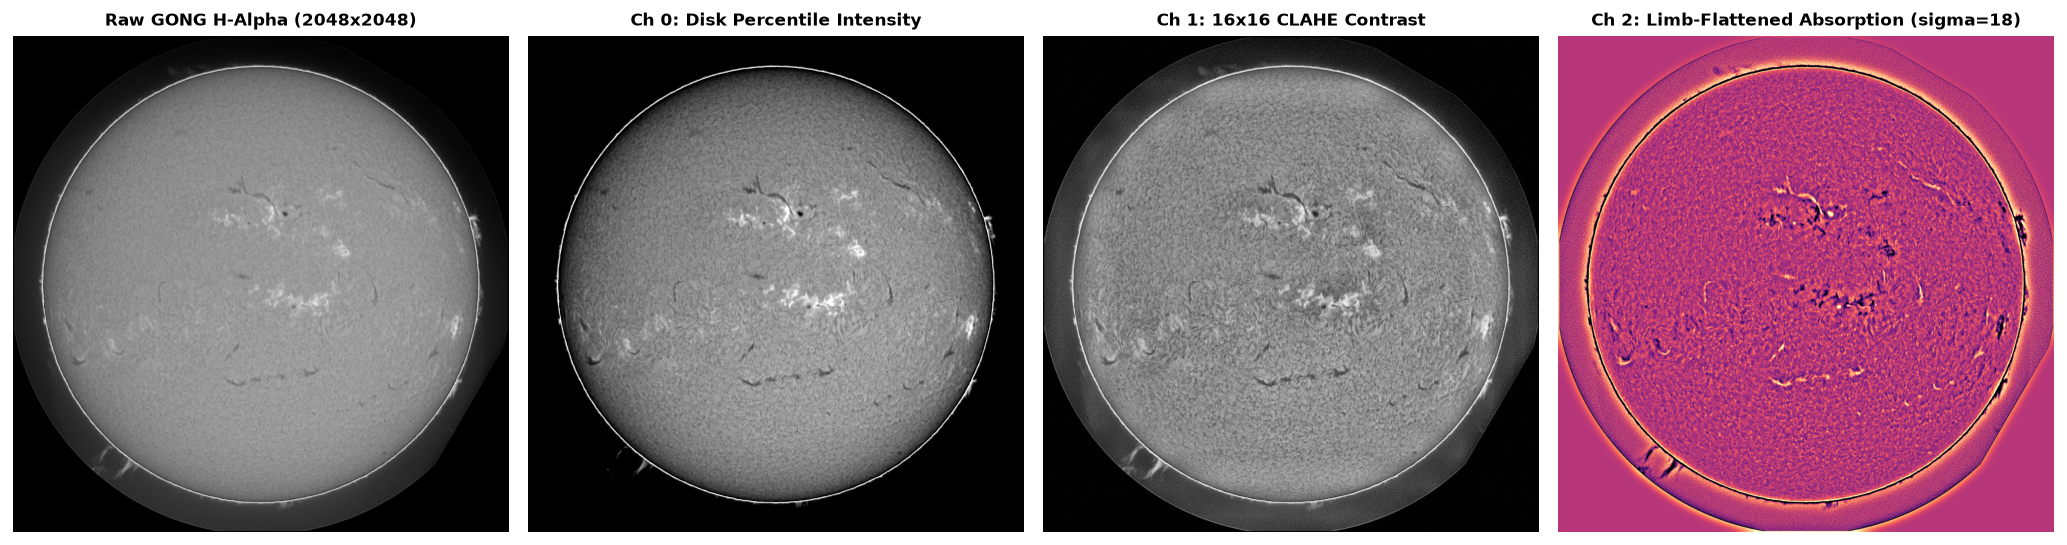

In [2]:
# Stage 1: Physical Three-Channel Solar Disk Normalization on GONG H-Alpha Observation
SAMPLE_IMG = Path("./samples/20140406195854Bh.jpeg")
raw_gray = cv2.imread(str(SAMPLE_IMG), cv2.IMREAD_GRAYSCALE)
assert raw_gray is not None and raw_gray.shape == (2048, 2048)


def normalize_solar_disk_3ch(gray: np.ndarray) -> np.ndarray:
    """Convert 2048x2048 grayscale H-alpha disk into physical 3-channel float32 tensor in [0, 1]."""
    h, w = gray.shape
    yy, xx = np.ogrid[:h, :w]
    disk_mask = (xx - w / 2.0) ** 2 + (yy - h / 2.0) ** 2 <= 940.0 ** 2
    disk_vals = gray[disk_mask].astype(np.float32)
    p10, p50, p90 = np.percentile(disk_vals, [10.0, 50.0, 90.0])
    iqr = max(float(p90 - p10), 1.0)

    ch0 = np.clip((gray.astype(np.float32) - p50) / (2.0 * iqr) + 0.5, 0.0, 1.0)
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(16, 16))
    ch1 = clahe.apply(gray).astype(np.float32) / 255.0
    bg = cv2.GaussianBlur(gray.astype(np.float32), (0, 0), sigmaX=18.0, sigmaY=18.0)
    ch2 = np.clip((bg - gray.astype(np.float32)) / iqr + 0.5, 0.0, 1.0)
    return np.stack([ch0, ch1, ch2], axis=-1)


norm_3ch = normalize_solar_disk_3ch(raw_gray)
print(f"Normalized tensor shape: {norm_3ch.shape}, dtype: {norm_3ch.dtype}, range: [{norm_3ch.min():.3f}, {norm_3ch.max():.3f}]")

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), dpi=130)
titles = [
    "Raw GONG H-Alpha (2048x2048)",
    "Ch 0: Disk Percentile Intensity",
    "Ch 1: 16x16 CLAHE Contrast",
    "Ch 2: Limb-Flattened Absorption (sigma=18)",
]
panels = [raw_gray, norm_3ch[:, :, 0], norm_3ch[:, :, 1], norm_3ch[:, :, 2]]
cmaps = ["gray", "gray", "gray", "magma"]
for ax, img_p, ttl, cm in zip(axes, panels, titles, cmaps):
    ax.imshow(img_p, cmap=cm)
    ax.set_title(ttl, fontsize=9.5, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()


Observers K = 3 | Naive 1-of-K Union px: 42,922 | Dinkelbach p0 px: 19,397 (Union bloat: 2.21x)
Compromise instances retained: 14 | Repulsion seam p3 pixels: 0


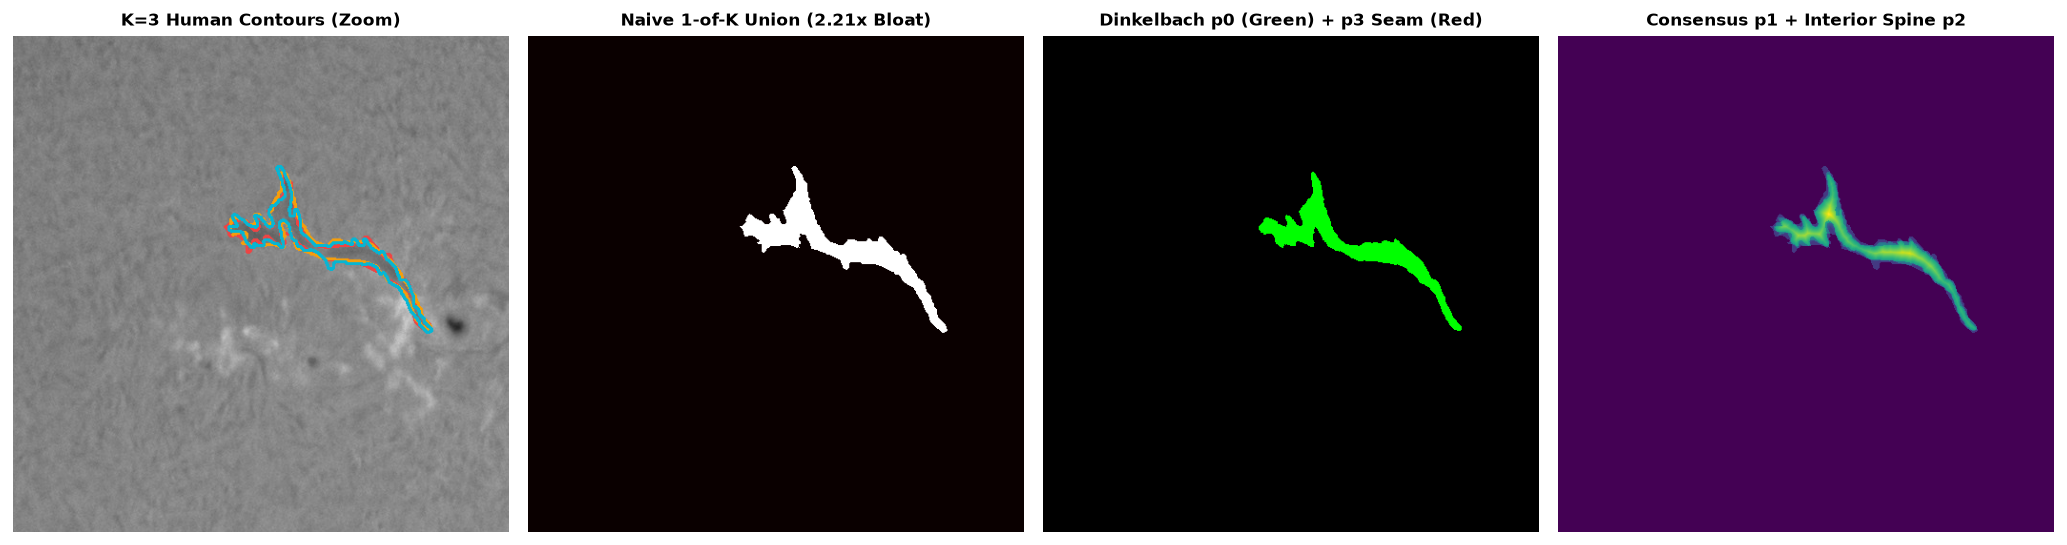

In [3]:
# Stage 2: Multi-Annotator Dinkelbach Signed-Distance Compromise vs. Naive 1-of-K Union
SAMPLE_ANN = Path("./samples/sample_annotations_20140406195854Bh.json")
coco_sub = json.loads(SAMPLE_ANN.read_text())

ann_by_img = {im["id"]: [] for im in coco_sub["images"]}
for an in coco_sub["annotations"]:
    rle = mu.frPyObjects(an["segmentation"], 2048, 2048)
    if isinstance(rle, list):
        rle = mu.merge(rle)
    m = mu.decode(rle).astype(np.uint8)
    if m.sum() > 0:
        ann_by_img[an["image_id"]].append(m)

K_obs = len(ann_by_img)
obs_masks = list(ann_by_img.values())
union_stack = [np.clip(sum(ms), 0, 1).astype(np.float32) for ms in obs_masks]
p1_consensus = sum(union_stack) / float(K_obs)
naive_union = (p1_consensus > 0).astype(np.uint8)

# Cluster cross-annotator instances at IoU >= 0.25 and extract SDF median compromise contours
all_inst = [(k, m) for k, ms in enumerate(obs_masks) for m in ms]
used = [False] * len(all_inst)
comp_instances = []
for i, (ki, mi) in enumerate(all_inst):
    if used[i]:
        continue
    cluster = [(ki, mi)]
    used[i] = True
    for j in range(i + 1, len(all_inst)):
        if used[j]:
            continue
        kj, mj = all_inst[j]
        inter = int((mi & mj).sum())
        if inter > 0 and inter / float((mi | mj).sum()) >= 0.25:
            cluster.append((kj, mj))
            used[j] = True
    # Signed Euclidean distance field average across K_obs
    sdf_sum = np.zeros((2048, 2048), dtype=np.float32)
    present_k = {}
    for kc, mc in cluster:
        present_k[kc] = np.maximum(present_k.get(kc, 0), mc)
    if len(present_k) / float(K_obs) >= 0.35:
        for kc in range(K_obs):
            if kc in present_k:
                mc = present_k[kc]
                pos = cv2.distanceTransform(mc, cv2.DIST_L2, 5)
                neg = cv2.distanceTransform(1 - mc, cv2.DIST_L2, 5)
                sdf_sum += pos - neg
            else:
                sdf_sum -= 4.0
        comp_m = (sdf_sum >= 0.0).astype(np.uint8)
        if comp_m.sum() >= 25:
            comp_instances.append(comp_m)

p0_compromise = np.zeros((2048, 2048), dtype=np.uint8)
p2_spine = np.zeros((2048, 2048), dtype=np.float32)
dil_sum = np.zeros((2048, 2048), dtype=np.uint8)
ker5 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
for cm in comp_instances:
    dt = cv2.distanceTransform(cm, cv2.DIST_L2, 5)
    if dt.max() > 0:
        p2_spine = np.maximum(p2_spine, dt / float(dt.max()))
    dil_sum += cv2.dilate(cm, ker5)
    p0_compromise = np.maximum(p0_compromise, cm)
p3_seam = (dil_sum >= 2).astype(np.uint8)
p0_compromise[p3_seam > 0] = 0

bloat_ratio = naive_union.sum() / max(float(p0_compromise.sum()), 1.0)
print(f"Observers K = {K_obs} | Naive 1-of-K Union px: {naive_union.sum():,} | Dinkelbach p0 px: {p0_compromise.sum():,} (Union bloat: {bloat_ratio:.2f}x)")
print(f"Compromise instances retained: {len(comp_instances)} | Repulsion seam p3 pixels: {int(p3_seam.sum()):,}")

# Zoom into active filament belt (520x520 crop)
y0, x0, sz = 430, 660, 520
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), dpi=130)
crop_bg = cv2.cvtColor(raw_gray[y0:y0+sz, x0:x0+sz], cv2.COLOR_GRAY2RGB)

ov_human = crop_bg.copy()
colors_k = [(239, 68, 68), (245, 158, 11), (6, 182, 212)]
for kc, ms in enumerate(obs_masks):
    for m in ms:
        cnts, _ = cv2.findContours(m[y0:y0+sz, x0:x0+sz], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(ov_human, cnts, -1, colors_k[kc % 3], 2)

axes[0].imshow(ov_human)
axes[0].set_title("K=3 Human Contours (Zoom)", fontsize=9.5, fontweight="bold")
axes[1].imshow(naive_union[y0:y0+sz, x0:x0+sz], cmap="hot")
axes[1].set_title(f"Naive 1-of-K Union ({bloat_ratio:.2f}x Bloat)", fontsize=9.5, fontweight="bold")

seam_rgb = np.zeros((sz, sz, 3), dtype=np.float32)
seam_rgb[:, :, 1] = p0_compromise[y0:y0+sz, x0:x0+sz]
seam_rgb[:, :, 0] = p3_seam[y0:y0+sz, x0:x0+sz]
axes[2].imshow(seam_rgb)
axes[2].set_title("Dinkelbach p0 (Green) + p3 Seam (Red)", fontsize=9.5, fontweight="bold")
axes[3].imshow(0.5 * p1_consensus[y0:y0+sz, x0:x0+sz] + 0.5 * p2_spine[y0:y0+sz, x0:x0+sz], cmap="viridis")
axes[3].set_title("Consensus p1 + Interior Spine p2", fontsize=9.5, fontweight="bold")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


Loaded ensemble_v4_config.json:
  Dense segmentation families : 6 (24 fold checkpoints)
  3-Channel YOLO11m-Seg folds : 4 (imgsz=1024, 3-ch=True)
  Topological feature count   : 60 full / 52 seg-only | Dual-GBDT alpha=0.6
  Exact MWIS parameters       : best_sources=[0, 1, 2, 3, 6, 7, 10], cut=0.22, split_cost=0.24
Verified ConvNeXt-Small fold0 tensors (402 params) & LightGBM booster (360 trees)
[  0.24m][main] CPU ROI fast calibration (n_imgs=1) selected 4 families -> /tmp/sf_cpu_cal_cfg_19620.json
[  0.45m][main] Worker initialized (4 seg families, 24+24 Stage-1 GBDTs, 2 YOLO ckpts [3ch=True], cut=0.22, split=0.24) on 1/1 test images
[  3.94m][main] Processed 1/1 shard images (instances: 10)
[  3.94m][main] Wrote outputs/sample_submission_demo.csv: 10 instances, 0 overlap pixels

[REPRODUCED] 10 pixel-disjoint filament instances predicted | Overlap pixels = 0


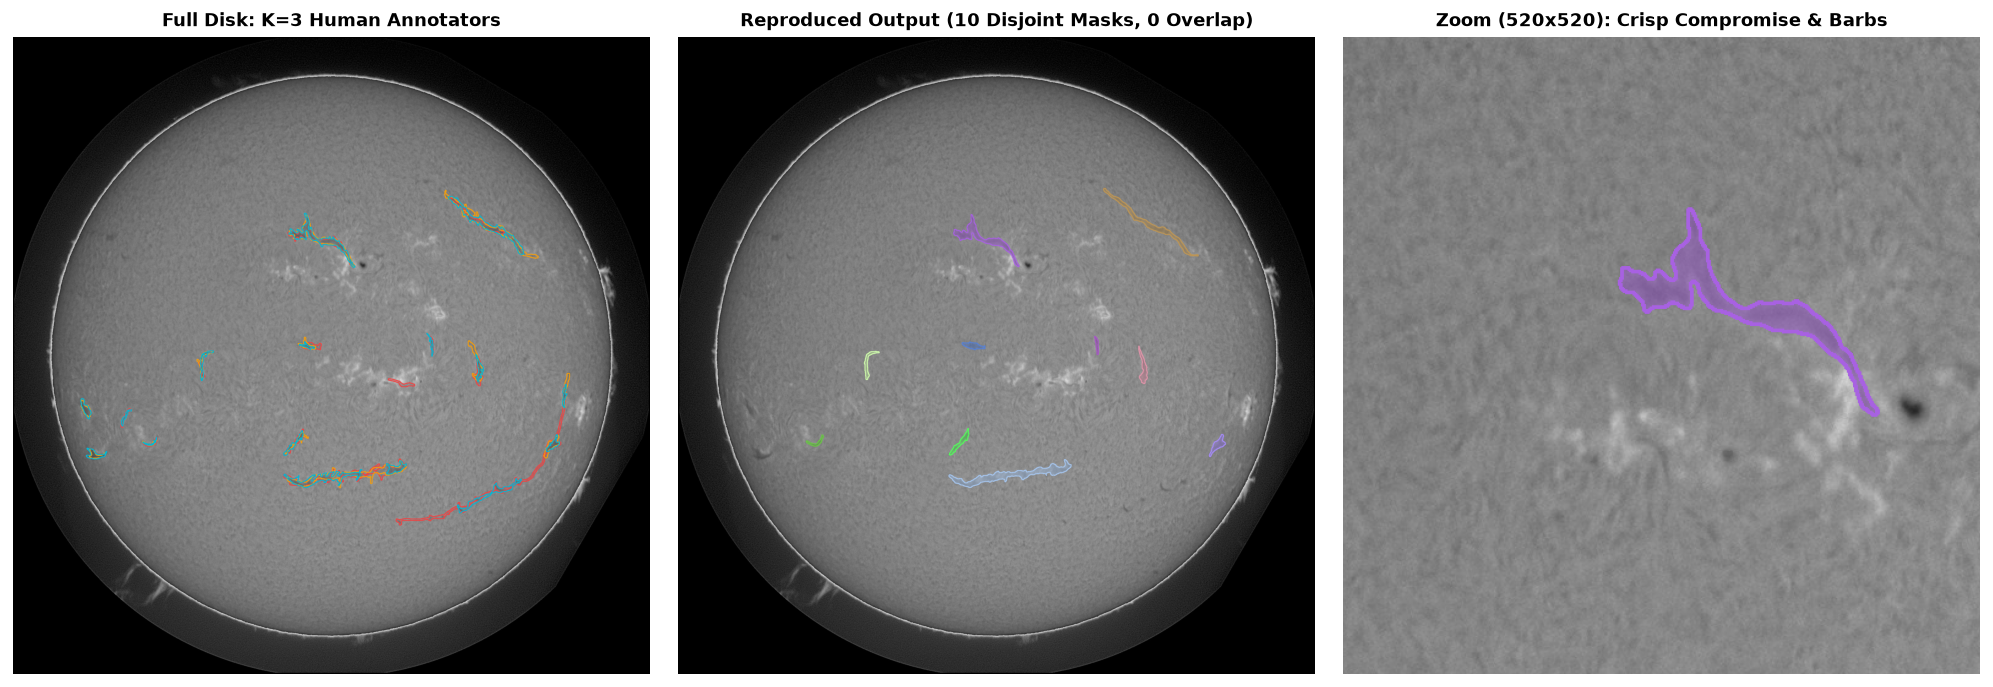

In [4]:
# Stages 3-5: Load Stored Pretrained Weights & Run Dynamic End-to-End Panoptic Inference
import subprocess
import sys

ens_cfg = json.loads((WEIGHTS_DIR / "ensemble_v4_config.json").read_text())
print("Loaded ensemble_v4_config.json:")
print(f"  Dense segmentation families : {len(ens_cfg['arch_groups'])} ({sum(len(g['ckpts']) for g in ens_cfg['arch_groups'])} fold checkpoints)")
print(f"  3-Channel YOLO11m-Seg folds : {len(ens_cfg['yolo_ckpts'])} (imgsz={ens_cfg['yolo_imgsz']}, 3-ch={ens_cfg['yolo_use_3ch']})")
print(f"  Topological feature count   : {len(ens_cfg['features'])} full / {len(ens_cfg['seg_features'])} seg-only | Dual-GBDT alpha={ens_cfg['yolo_gbdt_weight']}")
print(f"  Exact MWIS parameters       : best_sources={ens_cfg['best_sources']}, cut={ens_cfg['best_cut']}, split_cost={ens_cfg['split_cost']}")

# Verify direct PyTorch + LightGBM checkpoint loading before running full pipeline subprocess
sample_ckpt = torch.load(WEIGHTS_DIR / ens_cfg["arch_groups"][0]["ckpts"][0], map_location="cpu", weights_only=False)
sd = sample_ckpt["state_dict"] if isinstance(sample_ckpt, dict) and "state_dict" in sample_ckpt else sample_ckpt
sample_lgb = lgb.Booster(model_file=str(WEIGHTS_DIR / ens_cfg["selector_files"][0]))
print(f"Verified ConvNeXt-Small fold0 tensors ({len(sd)} params) & LightGBM booster ({sample_lgb.num_trees()} trees)")
del sample_ckpt, sd

OUT_DIR = Path("./outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
DEMO_CSV = OUT_DIR / "sample_submission_demo.csv"

env = os.environ.copy()
env["SF_ENS_CONFIG"] = "./weights/ensemble_v4_config.json"
env["SF_TEST_DIR"] = "./samples"
env["SF_OUT_CSV"] = "./outputs/sample_submission_demo.csv"

res = subprocess.run([sys.executable, "./src/inference_v4_panoptic.py"], env=env, capture_output=True, text=True)
assert res.returncode == 0, f"Inference failed:\n{res.stderr}\n{res.stdout}"
for ln in res.stdout.strip().splitlines()[-6:]:
    print(ln)

pred_df = pd.read_csv(DEMO_CSV)
rles = [{"size": [2048, 2048], "counts": str(c).encode("ascii")} for c in pred_df["segmentation_rle"]]
overlap_px = int(mu.area(rles).sum()) - int(mu.area(mu.merge(rles)))
assert overlap_px == 0, f"Expected 0 overlap pixels, got {overlap_px}"
print(f"\n[REPRODUCED] {len(pred_df)} pixel-disjoint filament instances predicted | Overlap pixels = {overlap_px}")

# Visualize reproduced pixel-disjoint masks vs K=3 human annotators
pred_vis = cv2.cvtColor(raw_gray, cv2.COLOR_GRAY2RGB)
rng = np.random.default_rng(42)
palette = rng.integers(70, 255, size=(len(rles) + 1, 3), dtype=np.uint8)
for idx, rle in enumerate(rles):
    m = mu.decode(rle).astype(np.uint8)
    col = tuple(int(c) for c in palette[idx])
    pred_vis[m > 0] = (0.55 * pred_vis[m > 0] + 0.45 * np.array(col)).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(pred_vis, cnts, -1, col, 2)

human_full = cv2.cvtColor(raw_gray, cv2.COLOR_GRAY2RGB)
for kc, ms in enumerate(obs_masks):
    for m in ms:
        cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(human_full, cnts, -1, colors_k[kc % 3], 2)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.2), dpi=130)
axes[0].imshow(human_full)
axes[0].set_title("Full Disk: K=3 Human Annotators", fontsize=10, fontweight="bold")
axes[1].imshow(pred_vis)
axes[1].set_title(f"Reproduced Output ({len(rles)} Disjoint Masks, 0 Overlap)", fontsize=10, fontweight="bold")
axes[2].imshow(pred_vis[y0:y0+sz, x0:x0+sz])
axes[2].set_title("Zoom (520x520): Crisp Compromise & Barbs", fontsize=10, fontweight="bold")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [5]:
# Stage 6: Official Panoptic Quality (PQ = SQ * RQ) Evaluation & 707-Stem OOF Benchmark
eval_dir = OUT_DIR / "sample_eval"
eval_cmd = [
    sys.executable,
    "./scripts/evaluate_official_pq.py",
    "--coco-json", str(SAMPLE_ANN),
    "--pred-csv", str(DEMO_CSV),
    "--out-dir", str(eval_dir),
]
ev_res = subprocess.run(eval_cmd, capture_output=True, text=True)
assert ev_res.returncode == 0, ev_res.stderr
print("=== Sample Disk Multi-Annotator Official Evaluation (K=3 Observers) ===")
print(ev_res.stdout.strip())

oof_metrics_path = Path("./technical_report/figures/official_pq_metrics.json")
if oof_metrics_path.exists():
    oof_m = json.loads(oof_metrics_path.read_text())
    print("\n=== Full 707-Stem Solar-Day-Grouped 4-Fold Out-Of-Fold Benchmark (1,949 Records) ===")
    for k, v in oof_m.items():
        print(f"  {k:18s}: {v}")


=== Sample Disk Multi-Annotator Official Evaluation (K=3 Observers) ===
{
  "PQ": 0.4671789607146473,
  "SQ": 0.681302651042194,
  "RQ": 0.6857142857142857,
  "TP": 24,
  "FP": 6,
  "FN": 16,
  "overlap_pixels": 0,
  "n_predictions": 10
}

=== Full 707-Stem Solar-Day-Grouped 4-Fold Out-Of-Fold Benchmark (1,949 Records) ===
  PQ                : 0.46324685493455275
  SQ                : 0.6868229427768331
  RQ                : 0.674477840040754
  TP                : 5296
  FP                : 2209
  FN                : 2903
  overlap_pixels    : 0
  n_predictions     : 4589


## Reproducing the Full 180-Disk Competition Submission & Optional Full Re-Training

### A. Full Competition Test-Set Inference (Using Stored Weights in `./weights` — No Re-Training Required)

Once `ensure_pretrained_weights()` above has populated `./weights`, run dynamic inference across all `180` competition test disks (`2048 x 2048`) with a single command:

```bash
BUNDLE_DIR=./weights \
TEST_DIR=/path/to/MAGFiLO_1.0_Kaggle_2026/test/test_images \
OUT_CSV=./submission.csv \
bash scripts/reproduce_infer.sh
```

* On `2x NVIDIA T4` GPUs, `src/inference_v4_panoptic.py` spawns two isolated worker processes (`CUDA_VISIBLE_DEVICES=0` and `1`), streams all `28` checkpoints with `4x` test-time augmentation in `54.2 min` (`< 3.2 GB` host RAM), and verifies `0` overlapping pixels in `./submission.csv`.
* On a `4`-vCPU host without GPUs, `src/inference_v4_panoptic.py` automatically engages calibrated native-scale YOLO region-of-interest packing (`< 56 min`).

### B. Full End-to-End 4-Fold Training From Scratch (Optional)

To regenerate all `24` dense segmentation checkpoints (`v4` 4-channel Dinkelbach + `v3` 3-channel consensus), `4` three-channel `YOLO11m-Seg` fold checkpoints, and `48` Dual-Anchored LightGBM boosters from the raw `MAGFiLO_1.0_Kaggle_2026` dataset:

```bash
DATA_ROOT=/path/to/MAGFiLO_1.0_Kaggle_2026 \
WORK_DIR=./outputs \
bash scripts/reproduce_train.sh
```
